지금까지 이미지 데이터에 중점을 두엇다. 대조적 언어 이미지 사전 학습(Contrastive Language-Image Pre-training)을 통해 오토 인코더와 VAE 방법에서 벗어나 이미지와 텍스트를 매칭하는 다른 기술을 살펴본다. 이 방법은 입력 데이터의 풍부한 표현을 생성한다는 점에서 유서하나 이미지와 텍스트를 동시에 처리할 수 있다는 장점이 있다. 

## 1. Contrastive Loss

CLIP은 Contrastive loss라는 손실함수를 사용한다. CLIP의 학습 데이터셋은 설며잉 포함된 수백만 개의 이미지로 구성되며 각 이미지-캡션 쌍에 대해 이미지 이노더를 사용해 이미지를 인코딩하여 latent space에서 임베딩 벡터를 생성한다. 그림의 $I_1, I_2, ..., I_n$ 상자는 각각 다른 이미지의 임베딩 벡터를 나타낸다. 텍스트도 인코딩되며 일반적으로 트랜스포머 모델이 사용된다. 중요한 점은 이미지와 텍스트 임베딩 벡터의 차원이 동일하도록 인코더를 학습한다는 것이다.   

이를 통해 텍스트와 이미지 임베딩 간의 inner product를 계산하여 두 벡터 간의 유사도를 측정한다. 


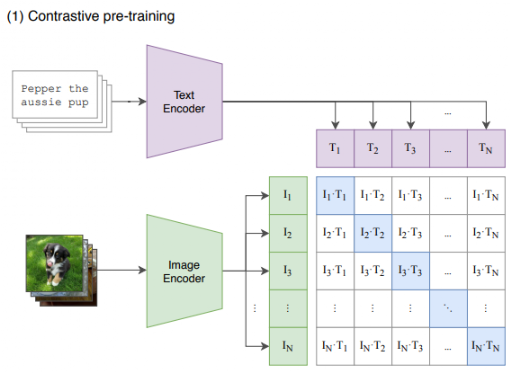

CLIP의 학습 과정에서는 한 번의 배치마다 여러 개의 이미지-텍스트 쌍이 입력된다. 배치 내 모든 이미지 임베딩과 모든 텍스트 임베딩 간의 내적을 계산한 후, 정답 쌍(즉, 원래 동일한 이미지-텍스트 쌍)의 내적값(그림의 파란색 대각선)이 최대화되도록 학습하고, 나머지 잘못된 쌍의 내적값은 최소화된다. 이러한 방식으로 의미적으로 유사한 이미지와 텍스트는 latent space 상에서 가까운 벡터로 표현되며, 서로 관련이 없는 개념들은 멀리 떨어진 벡터로 배치된다. 

## 2. 단계별로 CLIP 사용하기

이제 사전 학습된 CLIP 모델을 활용하여 작동 원리를 이해하고 실전에서 사용할 수 있는 몇 가지 예제를 살펴볼 것이다. 이를 위해 오픈 AI CLIP 모델 중 하나인 clip-vit-large-patch14를 사용한다. 이 모델은 이미지 인코더로 ViT를 사용하며 ResNet 기반 convolution 아키텍쳐를 사용하는 다른 버전도 존재한다.

In [29]:
import requests
from io import BytesIO
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
from genaibook.core import SampleURL, get_device

device = get_device()

model_id = "openai/clip-vit-large-patch14"
clip = CLIPModel.from_pretrained(model_id).to(device)
processor = CLIPProcessor.from_pretrained(model_id)

url = SampleURL.LionExample  # enum이면 필요시 SampleURL.LionExample.value
resp = requests.get(url, timeout=30)
resp.raise_for_status()


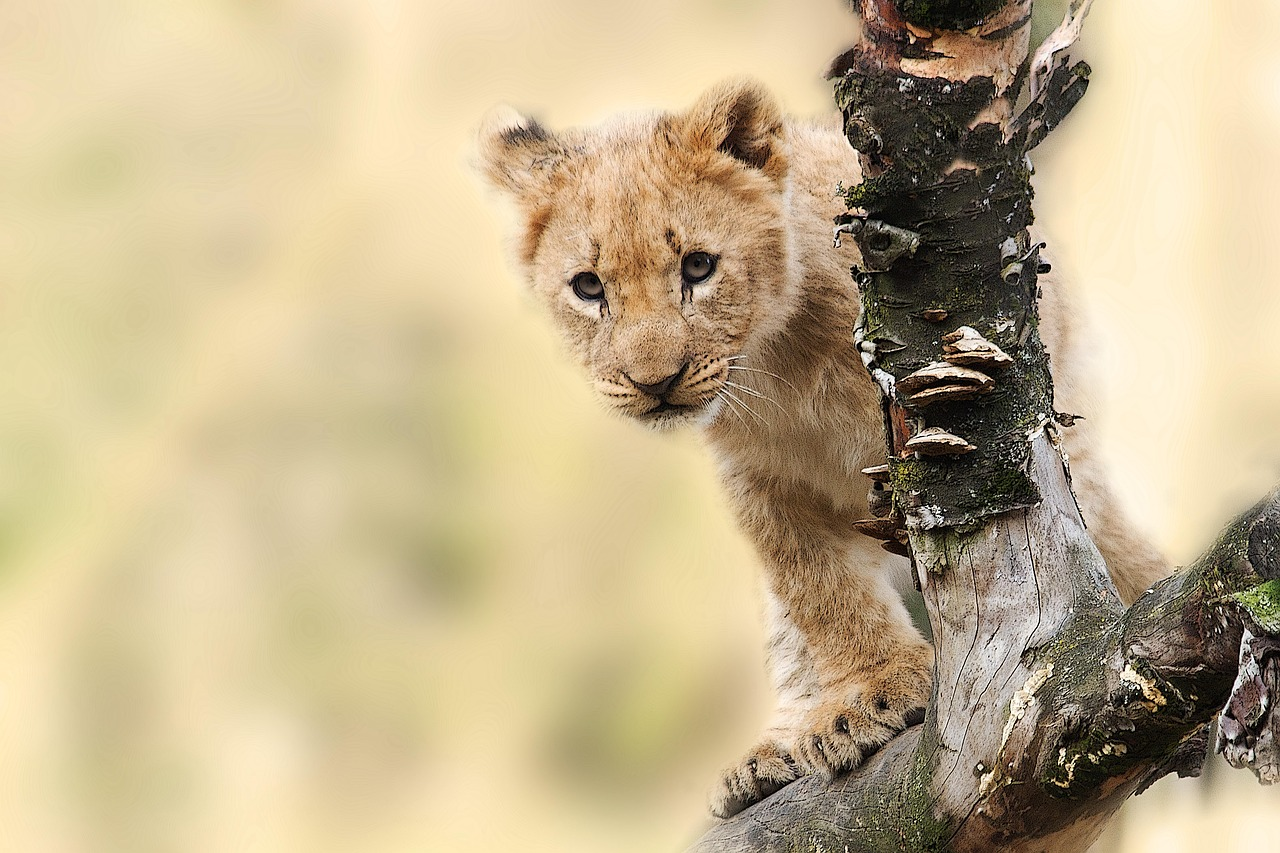

In [30]:
image = Image.open(BytesIO(resp.content)).convert("RGB")
image

로딩된 clip은 CLIP 모델로 이미지를 인코딩하는 비전 모델과 텍스트를 인코딩하는 텍스트 모델이라는 두 가지 요소를 포함한다. CLIPProcessor는 텍스트 토크나이저와 같은 기능을 수행하는 전처리 도구로, 모델 학습 중에 사용된 전처리 단계와 일치하도록 입력 데이터를 준비한다. 예를 들어 이미지 크기 조정, 정규화 등의 작업을 수해앟여 추론 시 입력데이터가 모델 학습 시 본 데이터와 동일한 특성을 유지하도록 한다. 

In [31]:
image_inputs = processor(images=image, return_tensors="pt")
pixel_values = image_inputs["pixel_values"]

pixel_values.shape, pixel_values.min(), pixel_values.max()

(torch.Size([1, 3, 224, 224]), tensor(-1.7923), tensor(1.9895))

이미지는 224 * 224의 정사각형의 크기가 조정된 후 정규화된다. 이미지 크기를 조정할 때는 가운데 자르기(center cropping)이 적용된다. 이 과정에서 잘려나가는 부분이 존재하고 이때 중요한 피사체가 있다면 정보 손실이 발생한다. 

In [32]:
processor.image_processor

CLIPImageProcessor {
  "crop_size": {
    "height": 224,
    "width": 224
  },
  "do_center_crop": true,
  "do_convert_rgb": true,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.48145466,
    0.4578275,
    0.40821073
  ],
  "image_processor_type": "CLIPImageProcessor",
  "image_std": [
    0.26862954,
    0.26130258,
    0.27577711
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 224
  }
}

crop 후 이미지가 잘려나갔는지 확인할 수 있다. 

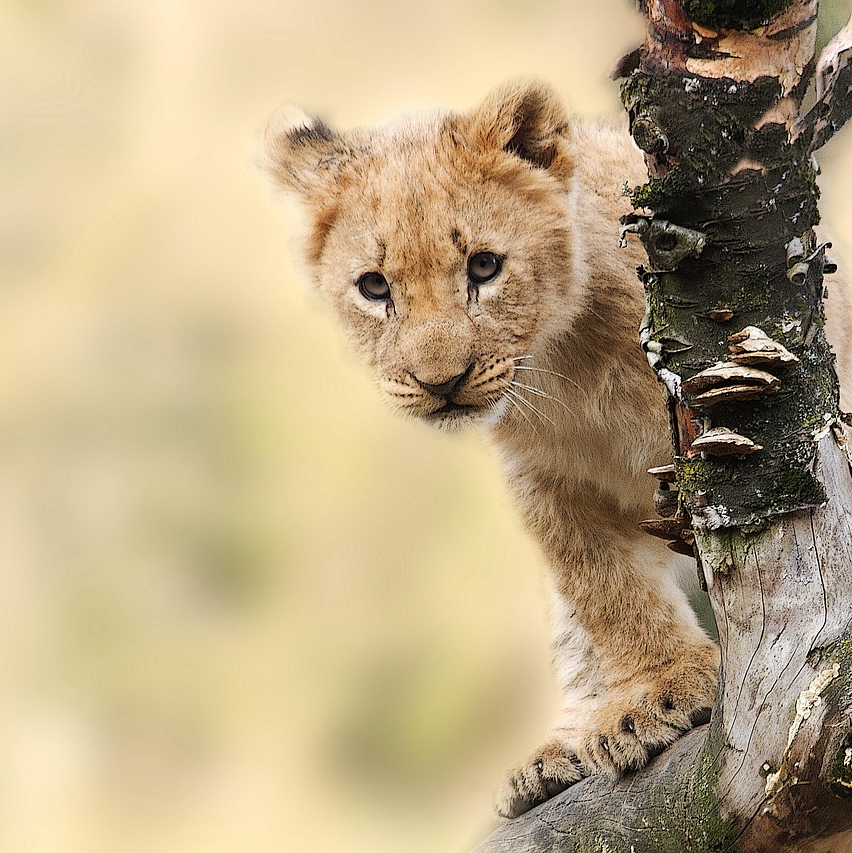

In [33]:
width, height = image.size
crop_length = min(image.size)

left = (width - crop_length) / 2
top = (height - crop_length) / 2
right = (width + crop_length) / 2
bottom = (height + crop_length) / 2

cropped = image.crop((left, top, right, bottom))
cropped

이제 전처리된 이미지에서 임베딩 벡터를 추출할 것이다. 이를 위해 clip instance에 저장된 비전 모델을 사용한다. 이 하위 구성요소는 종종 vision tower라고 불린다. 

In [34]:
import torch

with torch.inference_mode():
    outputs = clip.vision_model(pixel_values.to(device))
image_embeddings = outputs.pooler_output
image_embeddings.shape

torch.Size([1, 1024])

비전 모델의 마지막은 은닉 상태와 풀러 출력(pooler output)을 포함하는 딕셔너리를 반환한다. 이 [1, 1024] 형태는 벡터는 이미지가 인코딩된 결과를 나타낸다. 

이제 모델의 언어처리 부분을 살펴보자. 두 개의 텍스트 프롬프트 "a photo of lion", "a photo of a zebra"에 대한 임베딩을 생성하는 과정도 유사하다. 최종 목표는 이미지 임베딩과 각 프롬프트 임베딩 간의 코사인 유사도를 비교하는 것이다. 

In [35]:
prompts = [
    "a photo of a lion",
    "a photo of a zebra",
]

text_inputs = processor(text=prompts, return_tensors="pt", padding=True)
text_inputs

{'input_ids': tensor([[49406,   320,  1125,   539,   320,  5567, 49407],
        [49406,   320,  1125,   539,   320, 22548, 49407]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1]])}

입력 문자열을 토큰화하는 과정으로 시작된다. 이후 토큰화된 텍스트 입력을 모델의 언어 타워(language tower) 부분을 통해 변환하여 프롬프트 임베딩을 얻는다. 

In [36]:
text_inputs = {k: v.to(device) for k, v in text_inputs.items()}

with torch.inference_mode():
    text_outputs = clip.text_model(**text_inputs)

text_embeddings = text_outputs.pooler_output
text_embeddings.shape

torch.Size([2, 768])

두 개의 입력 프롬프트를 배치로 처리하여 각 임베딩 벡터를 생성한다. 이때 각 텍스트 임베딩 벡터는 768 차원이지만 이미지에서 얻은 임베딩 벡터의 차원은 1024 차원이다. 두 벡터의 내적을 계산하려면 차원 수가 동일해야 한다. 이 절의 초반에는 텍스트 인코더와 이미지 인코더가 동일한 차원의 임베딩을 생성해야한다고 하였지만, 몇 가지 추가과정을 거쳐야 한다. 같은 채원을 출력하는 인코더 모델을 선택하는 대신, 임의의 텍스트와 이미지 인코더를 사용하고 그 출력을 동일한 차원의 벡터로 변환하는 projection 과정을 거칠 수 있다. 이러한 projection 변환은 CLIP 학습 과정에 포함되었으며 앞서 내려받은 clip 모델 wrapper의 일부이기도 하다.

여기서 학습된 projection은 입력을 768 차원으로 변환하는 단순한 선형층이다. 텍스트 인코더와 비전 모델 각각을 위한 별도의 projection층이 있다. 

In [37]:
print(clip.text_projection)
print(clip.visual_projection)

Linear(in_features=768, out_features=768, bias=False)
Linear(in_features=1024, out_features=768, bias=False)


In [39]:
with torch.inference_mode():
    text_embeddings = clip.text_projection(text_embeddings)
    image_embeddings = clip.visual_projection(image_embeddings)
text_embeddings.shape, image_embeddings.shape

(torch.Size([2, 768]), torch.Size([1, 768]))

코사인 유사도를 계산하기 전에 벡터를 norm으로 정규화해야 한다. 임베딩을 적절히 스케일링 한 후 각 벡터의 크기로 나누어 정규화하면 되며, 이후 matrix multiplocation을 활용하여 두 개의 내적을 한 번에 계산할 수 있다. 

In [40]:
text_embeddings = text_embeddings / text_embeddings.norm(p=2, dim=-1, keepdim=True)
image_embeddings = image_embeddings / image_embeddings.norm(p=2, dim=-1, keepdim=True)
similarities = torch.chain_matmul(text_embeddings, image_embeddings.T)
similarities

tensor([[0.2226],
        [0.1936]], device='cuda:0')

학습 중에 이러한 코사인 유사도는 각 이미지-텍스트 쌍의 레이빌을 예측하는 cross-enthropy 손실 분류기에 입력될 logit(로짓, 신경망에서 확률을 예측하기 전에 사용하는 값으로, 소프트맥스 함수를 적용하기 전의 출력)으로 해석되었다. CLIP 학습은 32개의 크기로 된 배치를 사용하였으며 레이블은 배치 내의 32_768개 위치 각각을 나타낸다. 모델이 학습된 후 cross enthropy process에서 이미 이미지 $I_1$에 대한 클래스 $T_1$을, 이미지 $I_2$에 대한 클래스 $T_2$를 선택한다. 

하지만, 마지막으로 고려해야할 세부사항이있다. 벡터가 norm 되었으므로 logit 값은 $[-1, 1]$ 사이를 벗어날 수 없다. 그러나 부동 소숫점 표현의 한계 때문에 32K 개의 카테고리가 있는 확률 분포를 표현하기에는 이 분포가 부족할 수 있다. CLIP의 저자들은 학습 가능한 temperature(출력값을 조절하는 매개변수로 값이 클수록 예측 확률이 균등해지고 작을수록 높은 확률값이 두드러진다) 매개변수를 도입하여 logit의 범위를 확장해 이를 해결했다. 하지만 수치적 안정성을 유지하기 위해 이 temperature 역수 값인 scale의 값을 최대 100으로 제한했다. 학습을 진행한 모든 실험에서 이 값은 항상 100에 도달하였으며, 따라서 CLIP의 추론 과정에서는 logit을 확률로 변환하기 전에 scale factor 100을 적용한다. 

이제 이전 코드를 수정하여 scaling된 유사도 로짓(similarity logit)을 확류롤 변환할 수 있다. 이 확률은 이미지가 사용한 두 개의 텍스트 캠션 중 하나와 일치할 가능성을 나타낸다. |

In [41]:
similarities = 100 * torch.matmul(text_embeddings, image_embeddings.T)
similarities.softmax(dim=0).cpu()

tensor([[0.9479],
        [0.0521]])

모델이 "a photo of lion"이라는 프롬프트와 이미지를 0.9479의 신뢰도로 일치시켰음을 볼 수 있다. 

## 3. CLIP을 활용한 제로샷 이미지 분류

앞선 절을 통해 CLIP을 사용한 제로샷 분류 작업을 구현하는데 필요한 단계를 살펴볼 수 있었다. 다행히도 트랜스포머나 OpenCLIP같은 소프트웨어 라이브러리는 이 과정을 훨씬 쉽게 해 주는 더 높은 수준의 추상화를 제공해준다. 

이전 절의 예제를 상위 수준의 트랜스포머 API로 만들어보저. 이전과 동일한 방식으로 CLIP 모델, 프로세서, 텍스트 이미지를 불러온다. 

In [42]:
clip = CLIPModel.from_pretrained("openai/clip-vit-large-patch14").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")

image = Image.open(BytesIO(resp.content)).convert("RGB")

프로세서를 활용해 이미지와 텍스트 프롬프트 모두에 대한 입력을 동시에 계산할 수 있다. 또한 CLIP 모델을 전체 입력 세트와 함께 편리하게 호출하여 이미지와 각 프롬프트 간의 logit(또는 scaled cosine similarity)를 검색할 수 있다. 

In [45]:
prompts = [
    "a photo of a lion",
    "a photo of a zebra",
    "a photo of a cat",
    "a photo of an adorable lion cub",
    "a puppy",
    "a lion behind a branch",
]

inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)
inputs = {k: v.to(device) for k, v in inputs.items()}

outputs = clip(**inputs)
logits_per_image = outputs.logits_per_image
probabilities = logits_per_image.softmax(dim=1)
probabilities = probabilities[0].cpu().detach().tolist()

for prob, prompt in sorted(zip(probabilities, prompts), reverse=True):
    print(f"{100*prob:2.0f}%: {prompt}")

84%: a photo of an adorable lion cub
13%: a lion behind a branch
 3%: a photo of a lion
 0%: a photo of a zebra
 0%: a photo of a cat
 0%: a puppy


## 4. 제로샷 이미지 분류 파이프라인

이제 더 높은 수준의 API를 사용해 단순성과 편의성을 높일 수 있다. 1장에서 다룬 pipeline의 추상화를 활용해 볼 수 있다. 이전에는 텍스트 분류 작업에 적용하였으나 이를 제로샷 이미지 분류를 포함한 다양한 작업에 사용해 볼 수 있다. 

In [48]:
from transformers import pipeline

classifier = pipeline(
    "zero-shot-image-classification",
    model="openai/clip-vit-large-patch14",
    device=device,
)

Device set to use cuda


pipeline은 토큰화, 이미지 전처리, logit 후처리를 포함하여 모든 세부사항을 처리한다. 분류하고 싶은 이미지를 pipeline instance에 전달하고 후보 label set을 제공하면 된다. pipeline은 제공한 레이블과 관련된 모든 점수를 포함하는 dictionary를 반환하며, 이 값들은 편리하게 점수순으로 정렬된다. 

In [49]:
scores = classifier(
    image, 
    candidate_labels=prompts,
    hypothesis_template="{}",
)

hypothesis_template은 각 후보 레이블에 적용되어 분류를 위한 텍스트 프롬프트를 만드는 파이썬 형식 문자열이다. hypothesis_template 인수를 생략하면 pipeline은 자동으로 "This is a photo of a {}"를 사용하는데, 이는 'cat'이나 'lion'과 같은 이름으로 표시된 클래스 레이블을 형식화하는데 적합하다. 이미 CLIP과 잘 작동하는 프롬프트를 구성했으므로 {}를 사용해 레이블을 그대로 사용한다. 

In [50]:
scores

[{'score': 0.839290201663971, 'label': 'a photo of an adorable lion cub'},
 {'score': 0.12918104231357574, 'label': 'a lion behind a branch'},
 {'score': 0.02919217385351658, 'label': 'a photo of a lion'},
 {'score': 0.0016057792818173766, 'label': 'a photo of a zebra'},
 {'score': 0.0007013364229351282, 'label': 'a photo of a cat'},
 {'score': 2.9520917451009154e-05, 'label': 'a puppy'}]

## 5. CLIP의 대안

- 최근에는 더 나은 텍스트 이해가 더 뛰어난 텍스트-이미지 모델로 이어질 수 있다는 연구결과가 발표되었다(BLiP)
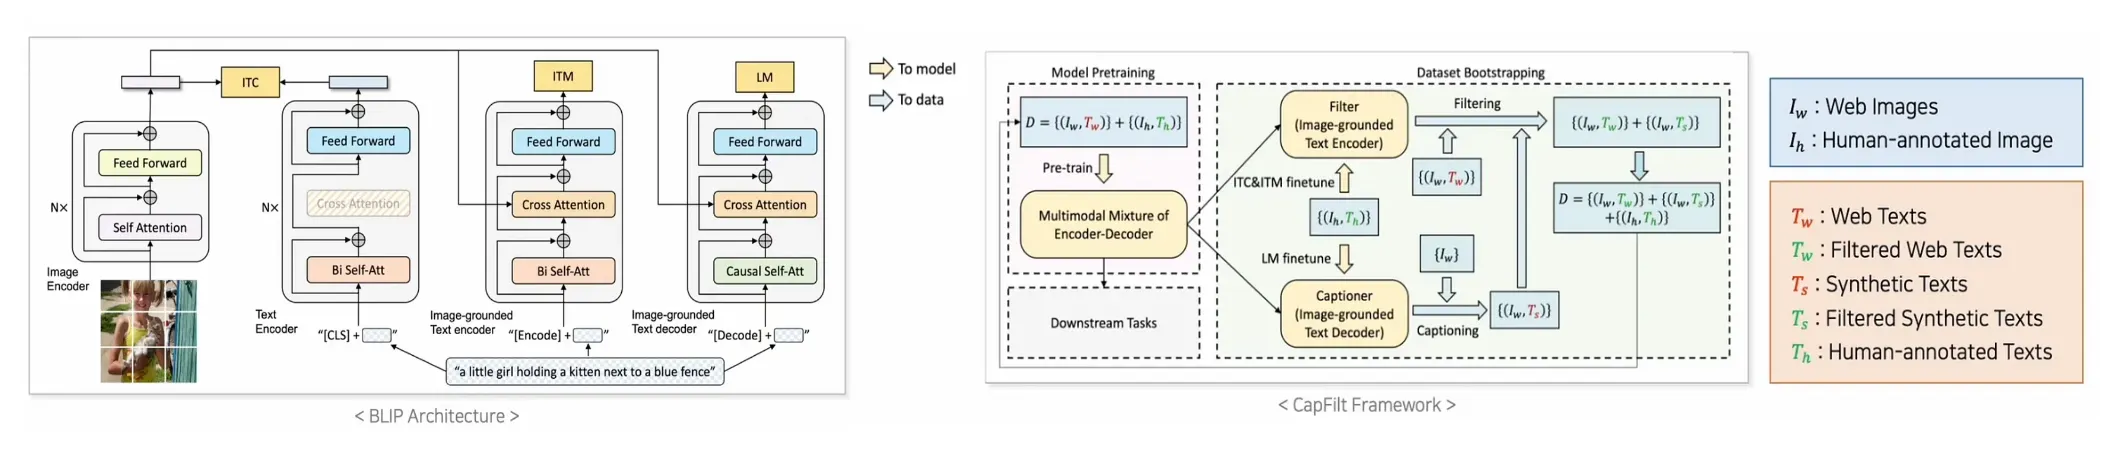

- SigLIP 에서는 기존 softmax norm 대신 sigmoid loss function을 적용해 clip 학습에서 요구되는 대규모 배치 크기의 부담을 줄이고 학습을 효율적으로 만드는 방법을 연구했다. 